# Classification

Many engineering decisions are categorical: a part is OK or not OK, a machine will fail within the next shift or not, a fault belongs to type A, B or C. Predicting such a category from measured data is called **classification**. It is the core of automated quality inspection, predictive maintenance and fault diagnosis.

Classification raises questions that regression does not. How do we measure the quality of a classifier when failures are rare? What is worse – a false alarm or a missed failure? And how do we choose the decision threshold that turns a predicted probability into an action? This chapter introduces three basic classifiers and, just as importantly, the metrics to evaluate them honestly.

::: {.scenario}
**Scenario: should we install the failure alarm?**

A milling line runs 10,000 operations per period. Every machine failure that is not anticipated costs about 10,000 € (scrap, repair, downtime). A vendor offers to install a failure alarm: when it fires, the machine is stopped and inspected, which costs about 500 € – whether or not a failure was imminent. Today there is no alarm at all, so every failure is unplanned. The plant manager wants a clear answer.

**Your decision:** Install an alarm – and if so, based on which model?
:::

**Learning goals.** After this chapter you can

- explain how logistic regression, k-nearest neighbours and decision trees classify,
- evaluate classifiers with confusion matrix, precision, recall, F1, ROC and precision–recall curves,
- handle strongly imbalanced classes with class weights, suitable metrics and threshold choice,
- choose a decision threshold based on the costs of errors,
- recognise and avoid data leakage.

**Datasets in this chapter**

- [AI4I 2020 Predictive Maintenance (UCI)](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

## Three ways to classify

In classification, the response $y$ takes one of $K$ classes; in the **binary** case $y \in \{0, 1\}$ (e.g. 1 = failure). Most classifiers estimate the probability $P(y = 1 \mid x)$ and predict class 1 if this probability exceeds a **threshold**, by default 0.5.

### Logistic regression

::: {.callout-note}
## Definition: Logistic regression
The probability of class 1 is modelled as
$$P(y = 1 \mid x) = \sigma(\beta_0 + \beta^\top x), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$
Equivalently, the **log-odds** are linear in the inputs: $\ln\frac{P(y=1\mid x)}{1 - P(y=1\mid x)} = \beta_0 + \beta^\top x$. The parameters are estimated by maximum likelihood.
:::

Logistic regression is the classification counterpart of linear regression: simple, fast, interpretable. A coefficient $\beta_j$ means that one unit more of $x_j$ multiplies the odds of failure by $e^{\beta_j}$ (the **odds ratio**). Its decision boundary – the set of $x$ where the probability equals the threshold – is a straight line (a hyperplane). Nonlinear boundaries require engineered features such as products or squares.

### k-nearest neighbours (kNN)

kNN stores the training data and classifies a new point by majority vote of its $k$ nearest training points. It makes no assumption about the shape of the boundary, but it depends entirely on the **distance measure** – inputs must be standardised, otherwise the input with the largest numerical range dominates. Small $k$ gives ragged boundaries (high variance), large $k$ smooth ones (high bias).

### Decision trees

A decision tree splits the input space step by step with simple rules such as "torque > 55 Nm". At each node, the split is chosen that makes the resulting groups as **pure** as possible, measured e.g. by the Gini impurity $G = 1 - \sum_k p_k^2$, where $p_k$ is the share of class $k$ in the node. Trees are easy to explain to colleagues and can capture interactions and thresholds, but a single deep tree overfits strongly; its depth must be limited. Chapter 8 shows how combining many trees fixes this.

![Decision boundaries of the three classifiers on a two-dimensional toy problem. Logistic regression draws a straight line, kNN follows the local structure of the data, and a decision tree uses axis-parallel steps.](images/decision-boundaries.png){#fig-boundaries width=100%}

## Evaluating classifiers

::: {.callout-note}
## Definition: Confusion matrix and derived metrics
|  | predicted OK (0) | predicted failure (1) |
| --- | --- | --- |
| **actual OK (0)** | true negative (TN) | false positive (FP) – false alarm |
| **actual failure (1)** | false negative (FN) – missed failure | true positive (TP) |

- **Accuracy** = (TP + TN) / all
- **Precision** = TP / (TP + FP): how many alarms are real?
- **Recall** (sensitivity, detection rate) = TP / (TP + FN): how many failures are detected?
- **F1 score** = harmonic mean of precision and recall
- **Balanced accuracy** = mean of the recall of both classes
:::

::: {.callout-warning}
## Pitfall: accuracy on imbalanced data
If 3 % of the records are failures, a "model" that always predicts "OK" reaches 97 % accuracy – and detects nothing. With rare events, accuracy is almost meaningless. Use precision, recall, F1 or balanced accuracy, and always look at the confusion matrix.
:::

Precision is nothing but $P(\text{failure} \mid \text{alarm})$ – Bayes' theorem from Chapter 3. When failures are rare, even a detector with high recall and a low false alarm rate can have a low precision.

### Thresholds, ROC and precision–recall curves

Lowering the threshold produces more alarms: recall increases, precision usually decreases. Instead of judging a single threshold, we can look at all thresholds at once:

- The **ROC curve** plots the true positive rate (recall) against the false positive rate FP/(FP + TN). The area under the curve (**ROC AUC**) is the probability that a randomly chosen failure gets a higher score than a randomly chosen OK record; 0.5 = random guessing, 1 = perfect ranking.
- The **precision–recall curve** plots precision against recall. For rare events it is more informative than ROC, because the false positive *rate* stays small even when the false alarms far outnumber the true alarms.

::: {.callout-tip}
## Engineering practice: choose the threshold by costs
The threshold 0.5 is arbitrary. If a missed failure costs $c_{FN}$ and a false alarm $c_{FP}$, choose the threshold that minimises the total cost $c_{FN} \cdot \text{FN} + c_{FP} \cdot \text{FP}$ – on validation data, not on the test data. For well-calibrated probabilities, the optimal threshold is $c_{FP}/(c_{FP} + c_{FN})$: if a miss is 20 times as expensive as a false alarm, alarm already at a failure probability of about 5 %.
:::

### Strategies for imbalanced classes

- **Stratified splitting:** keep the class proportions equal in training and test data (`stratify=y`).
- **Class weights:** weight errors on the rare class more strongly during training (`class_weight="balanced"`).
- **Resampling:** undersample the majority class or oversample the minority class (only in the training data!).
- **Threshold adjustment** as described above – often the simplest and most effective measure.

In [1]:
#| code-fold: false
# Setup: works locally and in Google Colab
import importlib.util, subprocess, sys
for pkg in ["ucimlrepo"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Live coding: predictive maintenance

The AI4I 2020 dataset is a synthetic dataset that reflects a real milling process. Each of the 10,000 records contains the product quality variant (L/M/H), air and process temperature, rotational speed, torque and tool wear, and the label `Machine failure`. The failures are generated by five documented mechanisms: tool wear failure (TWF), heat dissipation failure (HDF), power failure (PWF), overstrain failure (OSF) and random failures (RNF). Because the mechanisms are known, the dataset is ideal to check whether a model has learned something physically sensible.

In [2]:
#| code-fold: false
from ucimlrepo import fetch_ucirepo

ai4i = fetch_ucirepo(id=601).data.original

# Column names differ between versions of the dataset (with or without units in brackets,
# blanks or underscores). We map them to one canonical spelling with units.
import re
canonical = {"air temperature": "Air temperature [K]", "process temperature": "Process temperature [K]",
             "rotational speed": "Rotational speed [rpm]", "torque": "Torque [Nm]",
             "tool wear": "Tool wear [min]", "machine failure": "Machine failure", "type": "Type"}
def standardise(col):
    base = re.sub(r"[_\s]+", " ", str(col).split("[")[0]).strip().lower()
    return canonical.get(base, col)
ai4i = ai4i.rename(columns=standardise)
print("Columns:", ai4i.columns.tolist())

features = ["Type", "Air temperature [K]", "Process temperature [K]",
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
X = pd.get_dummies(ai4i[features], columns=["Type"], drop_first=True)
y = ai4i["Machine failure"]
print(f"Failure rate: {y.mean():.1%}")
# NOTE: the columns TWF, HDF, PWF, OSF, RNF describe the failure mode.
# Using them as features would be data leakage!

Columns: ['UID', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Failure rate: 3.4%


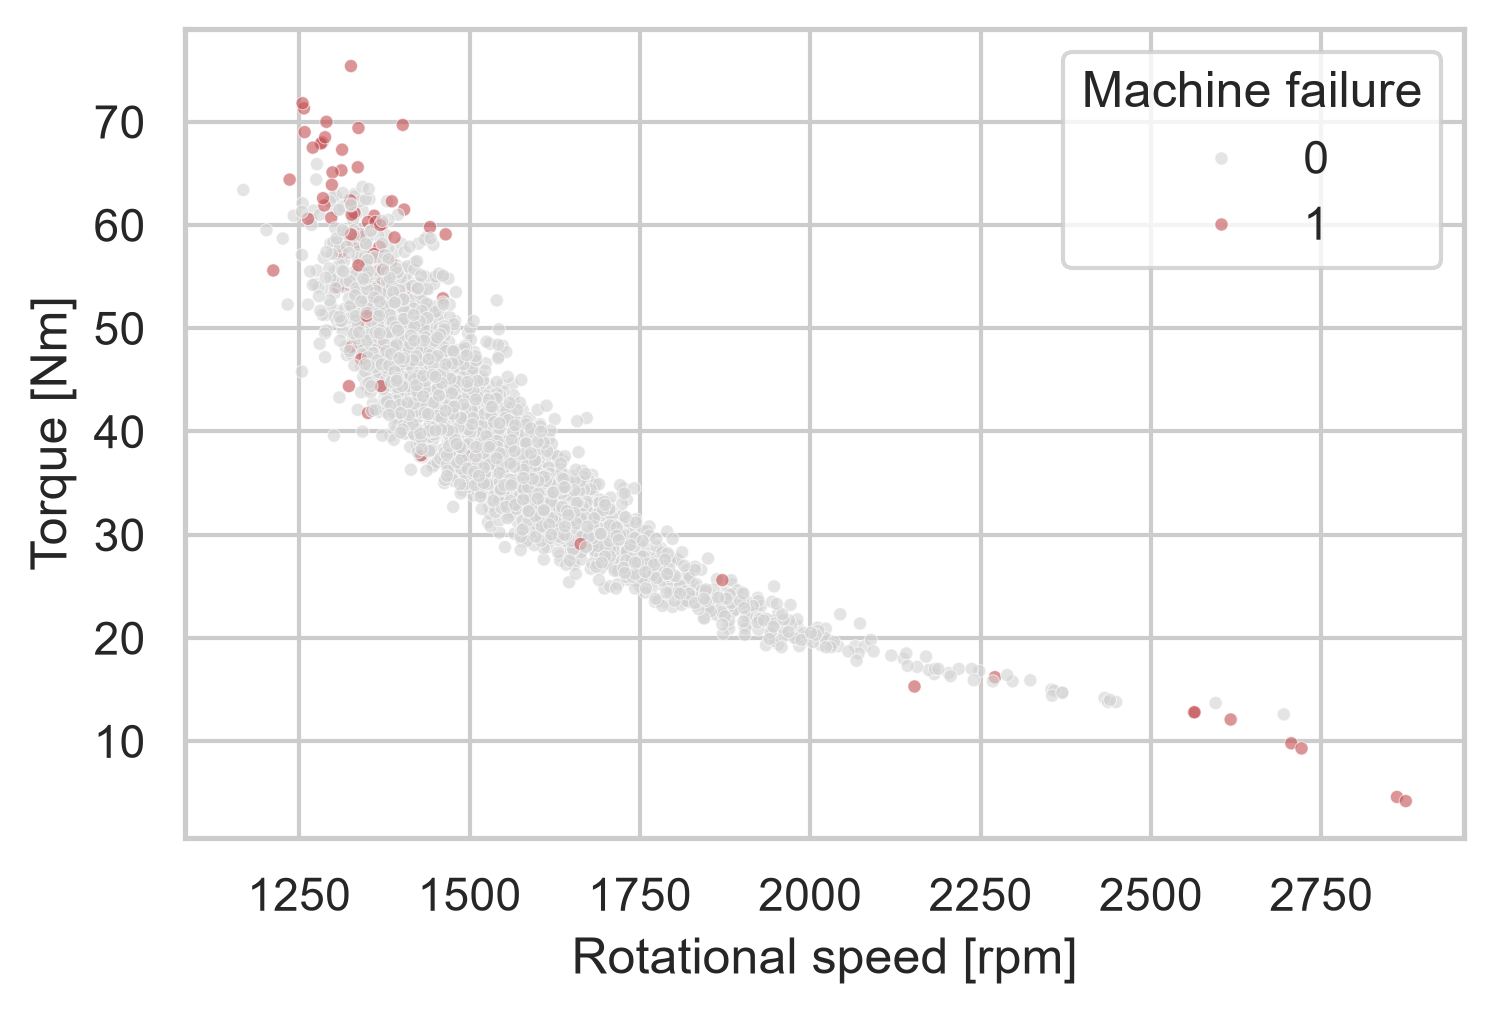

In [3]:
sns.scatterplot(data=ai4i.sample(3000, random_state=0), x="Rotational speed [rpm]", y="Torque [Nm]",
                hue="Machine failure", s=10, alpha=0.6, palette=["lightgray", "C3"])
plt.show()

The failures are not spread randomly: they concentrate at very high torque with low speed and at very low torque with high speed – regions of high and low mechanical power. A linear boundary in this plane cannot separate them; this matters for the choice of model.

In [4]:
#| code-fold: false
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=0)

models = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000)),
    "kNN (k=5)": make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
    "decision tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=0),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print(f"--- {name}")
    print(classification_report(y_test, m.predict(X_test), digits=3))

--- logistic regression
              precision    recall  f1-score   support

           0      0.990     0.827     0.901      2415
           1      0.135     0.765     0.229        85

    accuracy                          0.825      2500
   macro avg      0.562     0.796     0.565      2500
weighted avg      0.961     0.825     0.878      2500

--- kNN (k=5)
              precision    recall  f1-score   support

           0      0.977     0.996     0.986      2415
           1      0.737     0.329     0.455        85

    accuracy                          0.973      2500
   macro avg      0.857     0.663     0.721      2500
weighted avg      0.969     0.973     0.968      2500

--- decision tree
              precision    recall  f1-score   support

           0      0.994     0.935     0.964      2415
           1      0.311     0.835     0.454        85

    accuracy                          0.932      2500
   macro avg      0.653     0.885     0.709      2500
weighted avg      

**Discussion.** Read the reports row by row: the line for class 1 (failure) is the interesting one. Typically, logistic regression with class weights detects many failures (high recall) but raises many false alarms (low precision), because its linear boundary cannot isolate the failure regions. kNN without class weights is conservative: few false alarms, but many missed failures. The decision tree can represent the thresholds in torque, speed and tool wear that generate the failures and usually achieves the best balance. The accuracy row is high for all models – and says little.

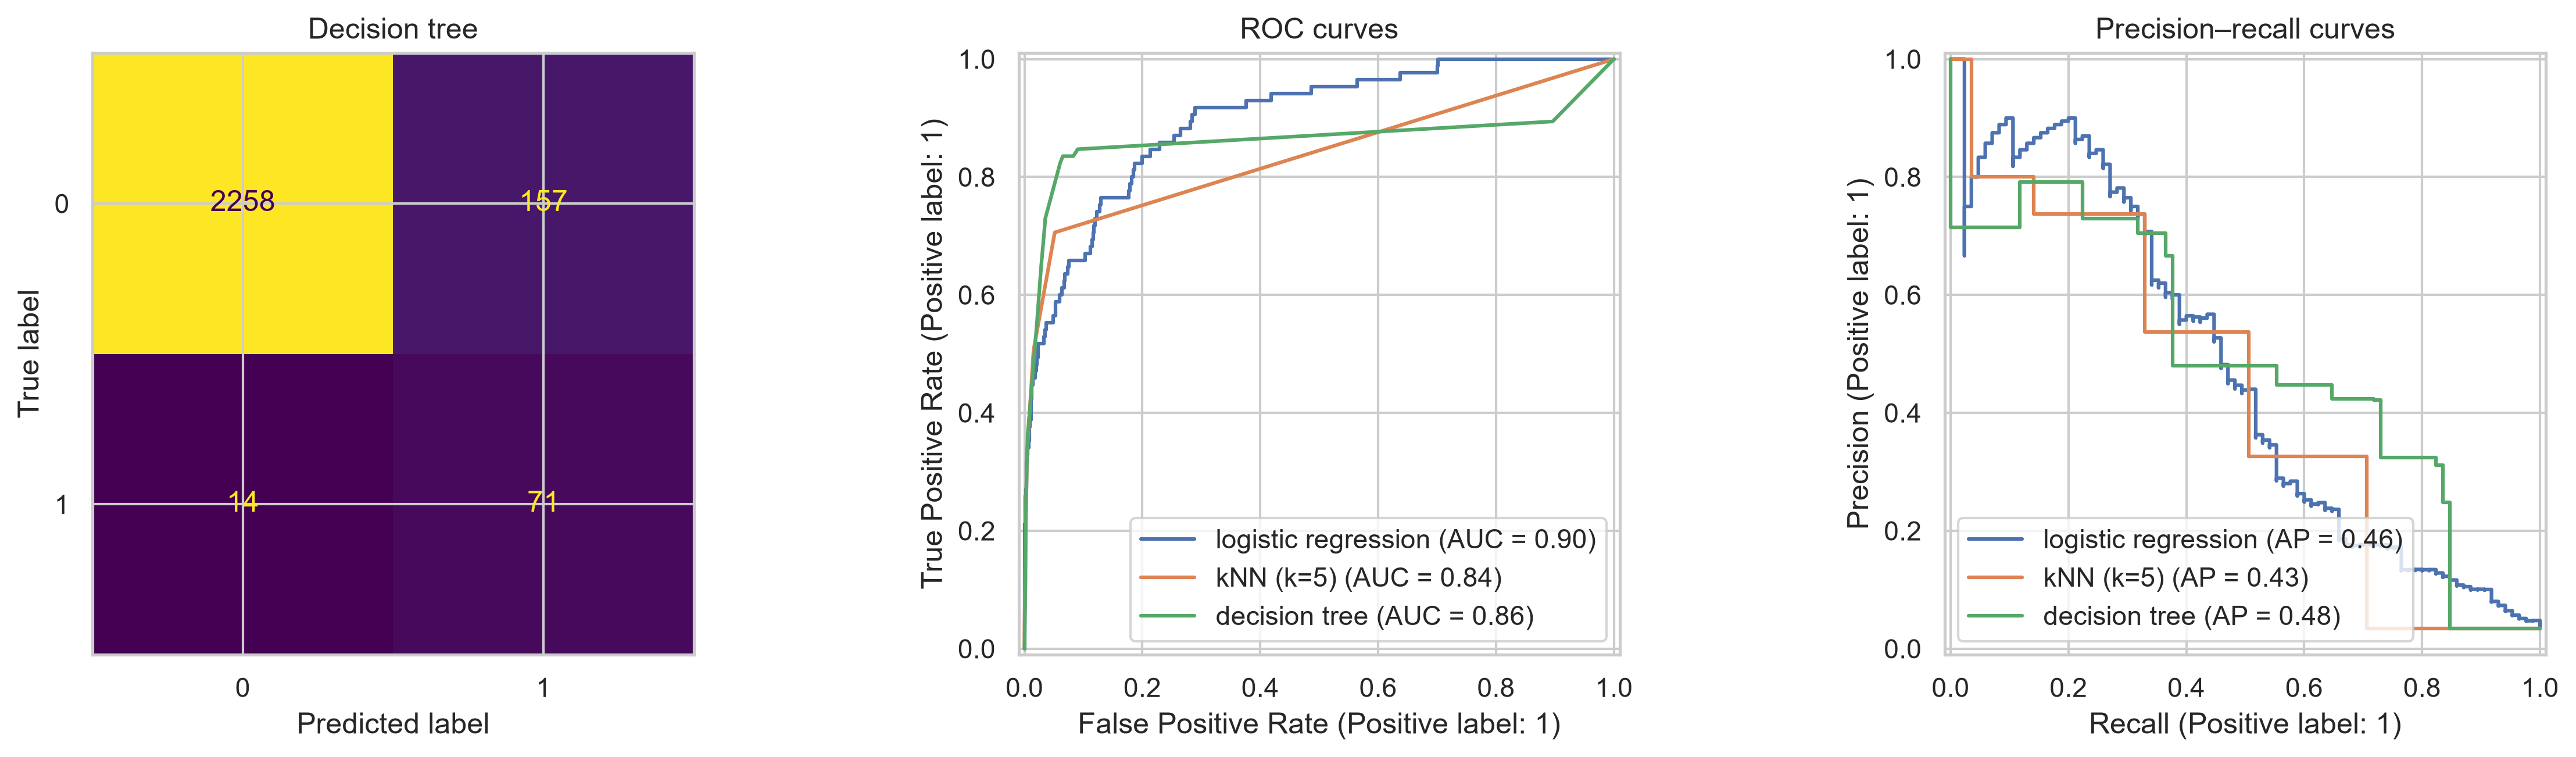

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ConfusionMatrixDisplay.from_estimator(models["decision tree"], X_test, y_test, ax=axes[0], colorbar=False)
axes[0].set_title("Decision tree")
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=axes[1], name=name)
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, ax=axes[2], name=name)
axes[1].set_title("ROC curves"); axes[2].set_title("Precision–recall curves")
plt.tight_layout(); plt.show()

**Discussion.** The ROC curves may look reassuringly good for all models, while the precision–recall curves reveal clear differences – the typical picture for rare events. The precision–recall curve directly shows the trade-off an engineer faces: "If I want to catch 80 % of the failures, how many of my alarms will be false?"

## Back to the decision

We compare the total cost per test period for the status quo (every failure is a missed failure) and for each model at its default threshold. A missed failure costs 10,000 €, a false alarm 500 €. Detected failures are assumed to be prevented and to cost only the inspection.

In [6]:
#| code-fold: false
from sklearn.metrics import confusion_matrix

c_fn, c_fp = 10_000, 500
status_quo = c_fn * int(y_test.sum())
costs = {}
for name, m in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, m.predict(X_test)).ravel()
    costs[name] = c_fn * fn + c_fp * (fp + tp)          # every alarm triggers an inspection
print(f"{'status quo (no alarm)':22s} {status_quo / 1000:8.1f} k€")
for name, c in costs.items():
    print(f"{name:22s} {c / 1000:8.1f} k€")
best = min(costs, key=costs.get)
if costs[best] < status_quo:
    print(f"Decision: install the alarm based on the {best} – saving {(status_quo - costs[best]) / 1000:.1f} k€ "
          f"({1 - costs[best] / status_quo:.0%}) per test period.")
else:
    print("Decision: no model beats the status quo – do not install.")

status quo (no alarm)     850.0 k€
logistic regression       441.5 k€
kNN (k=5)                 589.0 k€
decision tree             254.0 k€
Decision: install the alarm based on the decision tree – saving 596.0 k€ (70%) per test period.


The cost comparison translates the confusion matrix into the language of the plant manager. Exercise 2 shows that choosing the threshold by cost improves the result further. Before the final decision, two things should be checked: the AI4I data are *simulated*, so the savings must be confirmed in a pilot on the real line; and the assumption that every detected failure can be prevented is optimistic.

::: {.callout-important}
## Key takeaways
- Classifiers estimate class probabilities; a threshold turns them into decisions – choose it by the costs of errors.
- Logistic regression: linear boundary, interpretable; kNN: local, needs scaling; trees: thresholds and interactions, must be kept shallow.
- With rare events, accuracy and ROC can look good while the model is useless – use precision, recall and precision–recall curves.
- Features that encode the outcome (here: the failure mode columns) cause data leakage.
:::

## Exercises

<div class="exercises">

1. Add the failure mode columns (TWF, HDF, PWF, OSF, RNF) as features and retrain the decision tree. What happens to the scores – and why is this result worthless?
2. Assume a missed failure costs 10,000 € and a false alarm 500 €. Choose the decision threshold of the logistic regression that minimises the total cost. Use a validation split of the training data, not the test data.
3. Visualise the decision tree (`sklearn.tree.plot_tree`, depth 3). Do the rules make physical sense?
4. Construct the feature `power [W]` = torque × angular velocity and the temperature difference between process and air. Do they improve the logistic regression? Why?
5. A test set has TN = 950, FP = 30, FN = 5, TP = 15. Compute accuracy, precision, recall and F1 by hand. Is the model useful?

</div>

### Solutions

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 1

In [7]:
#| code-fold: false
X_leak = X.join(ai4i[["TWF", "HDF", "PWF", "OSF", "RNF"]])
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(X_leak, y, test_size=0.25, stratify=y, random_state=0)
tree_leak = DecisionTreeClassifier(max_depth=5, random_state=0).fit(Xl_tr, yl_tr)
print(classification_report(yl_te, tree_leak.predict(Xl_te), digits=3))

              precision    recall  f1-score   support

           0      0.998     1.000     0.999      2415
           1      1.000     0.941     0.970        85

    accuracy                          0.998      2500
   macro avg      0.999     0.971     0.984      2500
weighted avg      0.998     0.998     0.998      2500



Precision and recall jump to nearly 100 %. The failure mode columns are only known *after* a failure has been diagnosed – they essentially encode the label. In operation, at prediction time, they are not available. Such leakage produces impressive but completely useless models. Rule: for each feature, ask "Would I know this value at the moment I need the prediction?"
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 2

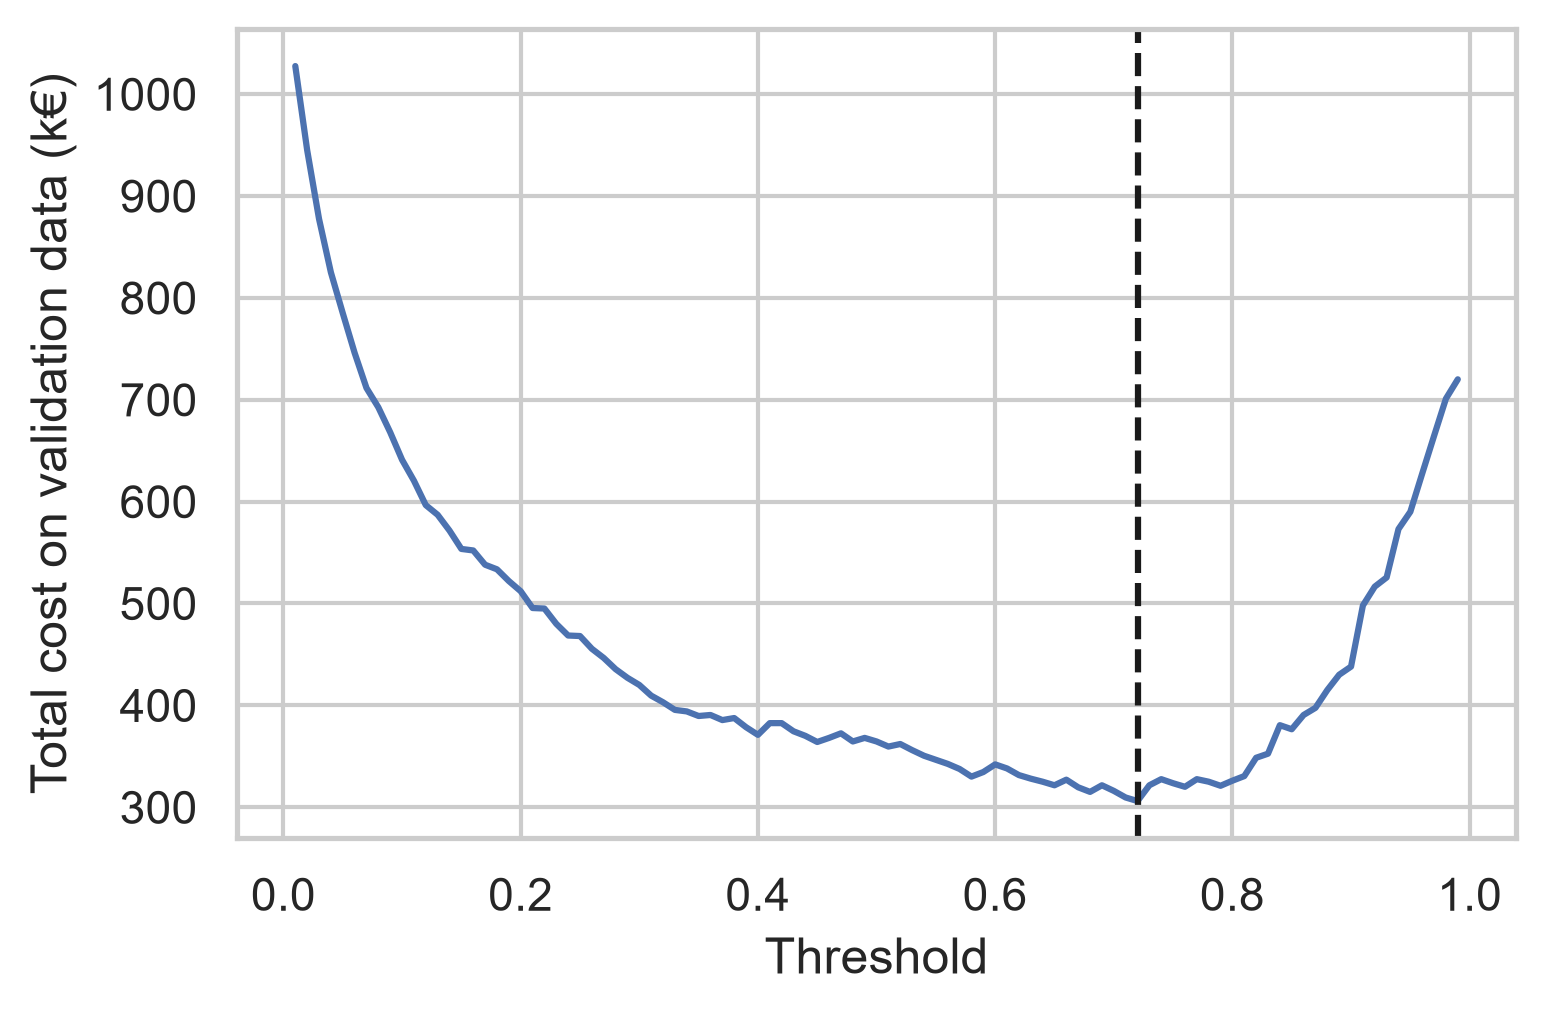

best threshold 0.72, cost on test data 404 k€


In [8]:
#| code-fold: false
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.3,
                                              stratify=y_train, random_state=1)
logreg = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))
logreg.fit(X_fit, y_fit)
p_val = logreg.predict_proba(X_val)[:, 1]

c_fn, c_fp = 10_000, 500
thresholds = np.linspace(0.01, 0.99, 99)
cost = [c_fn * ((p_val < t) & (y_val == 1)).sum() + c_fp * ((p_val >= t) & (y_val == 0)).sum()
        for t in thresholds]
t_best = thresholds[np.argmin(cost)]
plt.plot(thresholds, np.array(cost) / 1000)
plt.axvline(t_best, ls="--", c="k")
plt.xlabel("Threshold"); plt.ylabel("Total cost on validation data (k€)")
plt.show()

p_test = logreg.predict_proba(X_test)[:, 1]
cost_test = c_fn * ((p_test < t_best) & (y_test == 1)).sum() + c_fp * ((p_test >= t_best) & (y_test == 0)).sum()
print(f"best threshold {t_best:.2f}, cost on test data {cost_test / 1000:.0f} k€")

The cost curve typically has a broad minimum. Note that with `class_weight="balanced"` the predicted probabilities are no longer calibrated (the model behaves as if failures were as frequent as OK records), so the optimal threshold differs from the theoretical $c_{FP}/(c_{FP}+c_{FN}) \approx 0.048$. Choosing the threshold on validation data and reporting the cost on the untouched test data keeps the evaluation honest.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 3

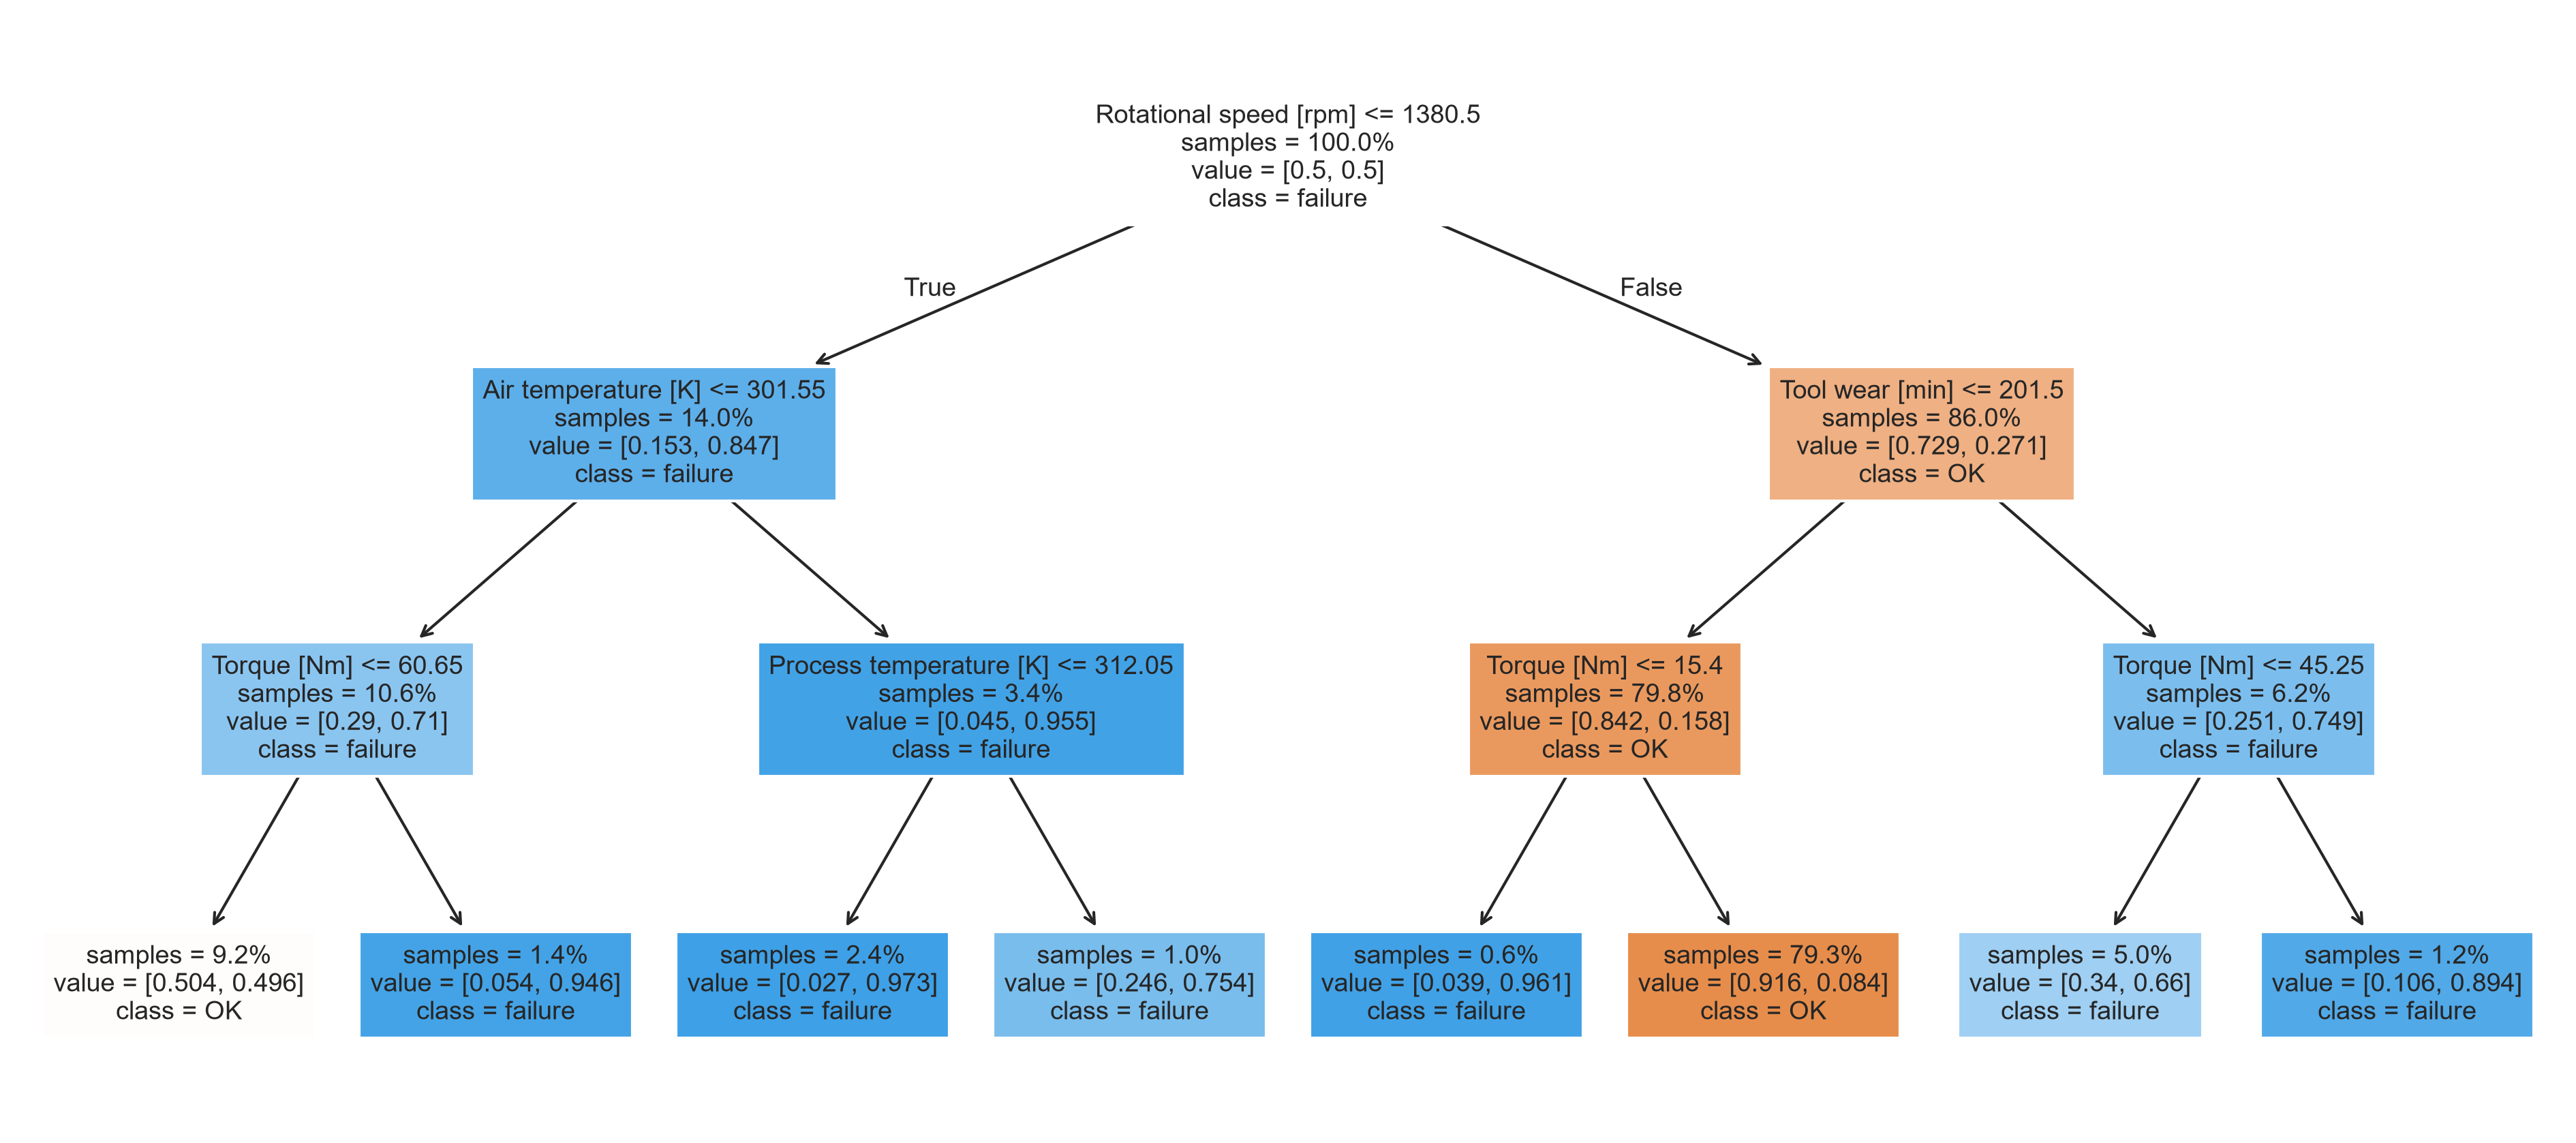

In [9]:
#| code-fold: false
from sklearn.tree import plot_tree

tree3 = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=0).fit(X_train, y_train)
plt.figure(figsize=(16, 7))
plot_tree(tree3, feature_names=X.columns, class_names=["OK", "failure"], filled=True,
          impurity=False, proportion=True, fontsize=9)
plt.show()

The top splits typically use torque, rotational speed and tool wear – exactly the quantities behind the documented failure mechanisms: overstrain (high torque × tool wear), power failure (power too low or too high, i.e. extreme torque–speed combinations) and tool wear failure (large tool wear). A tree that splits mainly on product ID or random variables would be suspicious. Checking learned rules against physics is one of the best plausibility tests for a model.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 4

In [10]:
#| code-fold: false
X_eng = X.copy()
X_eng["power [W]"] = ai4i["Torque [Nm]"] * ai4i["Rotational speed [rpm]"] * 2 * np.pi / 60
X_eng["delta T [K]"] = ai4i["Process temperature [K]"] - ai4i["Air temperature [K]"]
X_eng["strain [min Nm]"] = ai4i["Tool wear [min]"] * ai4i["Torque [Nm]"]

from sklearn.model_selection import cross_val_score, StratifiedKFold
skf = StratifiedKFold(5, shuffle=True, random_state=0)
for name, data in [("original features", X), ("with engineered features", X_eng)]:
    s = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000)),
                        data, y, cv=skf, scoring="average_precision")
    print(f"{name:26s} average precision = {s.mean():.3f}")

original features          average precision = 0.429


with engineered features   average precision = 0.453


Engineered features based on physics can help logistic regression a lot, because they turn curved boundaries into simpler ones. But power failures occur for *both* too low and too high power – a linear model in `power` can only represent one side. Squared or binned terms, or a tree-based model, are needed to capture both. This is a typical example of how domain knowledge and model choice interact.
:::

::: {.callout-caution .solution collapse="true"}
## Solution to Exercise 5
Total = 1000. Accuracy = (950 + 15)/1000 = 96.5 %. Precision = 15/(15 + 30) = 33 %. Recall = 15/(15 + 5) = 75 %. F1 = 2 · 0.33 · 0.75/(0.33 + 0.75) ≈ 0.46.

The accuracy is lower than that of the trivial model "always OK" (98 %)! Still, the model may be useful: it detects three of four failures, at the price of two false alarms per real one. Whether that is acceptable depends on the costs – if a missed failure is expensive and checking an alarm is cheap, this model is valuable despite its "bad" accuracy.
:::